In [1]:
%pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
X_train = pd.read_csv('X_train_cyto.csv')
X_test = pd.read_csv('X_test_cyto.csv')
y_train = pd.read_csv('y_train_cyto.csv')
y_test = pd.read_csv('y_test_cyto.csv')

# Drop sn
X_train = X_train.drop('sn', axis=1)
X_test = X_test.drop('sn', axis=1)

In [4]:
y_train['binary_target'] = (y_train['viability_%'] < 70).astype(int)
y_test['binary_target'] = (y_test['viability_%'] < 70).astype(int)

In [5]:
y_train_binary = y_train.drop('viability_%', axis=1)
y_test_binary = y_test.drop('viability_%', axis=1)

/tmp/ipykernel_2356/2646418997.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(ax=axes[0], x='binary_target', data=y_train_binary, palette='viridis')
/tmp/ipykernel_2356/2646418997.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['0 (Non-cytotoxic)', '1 (Cytotoxic)'])
/tmp/ipykernel_2356/2646418997.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.countplot(ax=axes[1], x='binary_target', data=y_test_binary, palette='viridis')
/tmp/ipykernel_2356/2646418997.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or

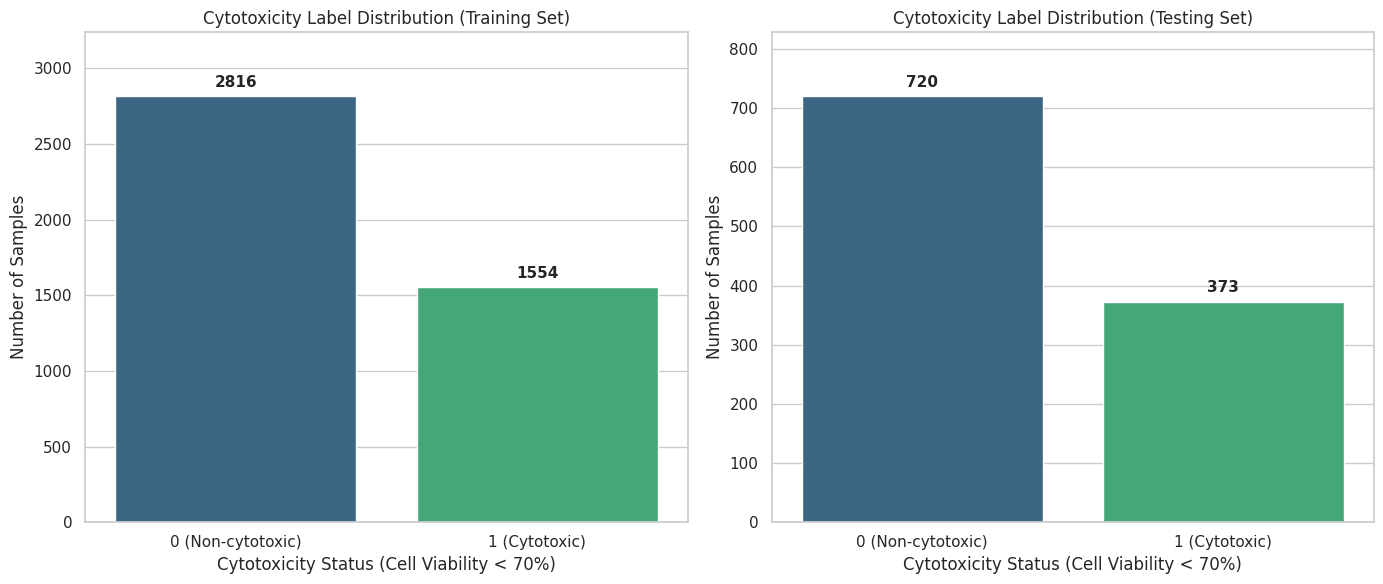

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)

# Plot 1: Training Set Distribution
ax1 = sns.countplot(ax=axes[0], x='binary_target', data=y_train_binary, palette='viridis')
axes[0].set_title('Cytotoxicity Label Distribution (Training Set)')
axes[0].set_xticklabels(['0 (Non-cytotoxic)', '1 (Cytotoxic)'])
axes[0].set_xlabel('Cytotoxicity Status (Cell Viability < 70%)')
axes[0].set_ylabel('Number of Samples')
axes[0].set_ylim(0, max(y_train_binary['binary_target'].value_counts()) * 1.15)

for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=11, fontweight='bold')

# Plot 2: Testing Set Distribution
ax2 = sns.countplot(ax=axes[1], x='binary_target', data=y_test_binary, palette='viridis')
axes[1].set_title('Cytotoxicity Label Distribution (Testing Set)')
axes[1].set_xticklabels(['0 (Non-cytotoxic)', '1 (Cytotoxic)'])
axes[1].set_xlabel('Cytotoxicity Status (Cell Viability < 70%)')
axes[1].set_ylabel('Number of Samples')
axes[1].set_ylim(0, max(y_test_binary['binary_target'].value_counts()) * 1.15)

for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [7]:
# Identify feature types
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [8]:
# Preprocessing
numeric_transformer = SimpleImputer(strategy='median')

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [9]:
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Logistic Regression': LogisticRegression(
        C=1.0,
        max_iter=10000,
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    ),

    'SVM': SVC(
        kernel='rbf',
        C=10,
        gamma='scale',
        probability=True,
        random_state=42
    )
}

In [10]:
results = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train_binary)

    pred = pipeline.predict(X_test)

    results[name] = pipeline
    predictions[name] = pred

    print(f"{name}: Training completed")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest: Training completed


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression: Training completed
XGBoost: Training completed


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVM: Training completed


In [11]:
evaluation = []

for name, pipeline in results.items():
    pred = predictions[name]

    pred_proba = pipeline.predict_proba(X_test)[:, 1]

    evaluation.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_binary, pred),
        'Precision': precision_score(y_test_binary, pred, zero_division=0),
        'Recall': recall_score(y_test_binary, pred, zero_division=0),
        'F1': f1_score(y_test_binary, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test_binary, pred_proba)
    })

evaluation_ml_sel_binary = pd.DataFrame(evaluation)
evaluation_ml_sel_binary = evaluation_ml_sel_binary.sort_values('F1', ascending=False)

display(evaluation_ml_sel_binary)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.873742,0.861538,0.750670,0.802292,0.929161
2,XGBoost,0.868253,0.856698,0.737265,0.792507,0.938496
1,Logistic Regression,0.766697,0.725191,0.509383,0.598425,0.821908
3,SVM,0.667887,0.812500,0.034853,0.066838,0.690183


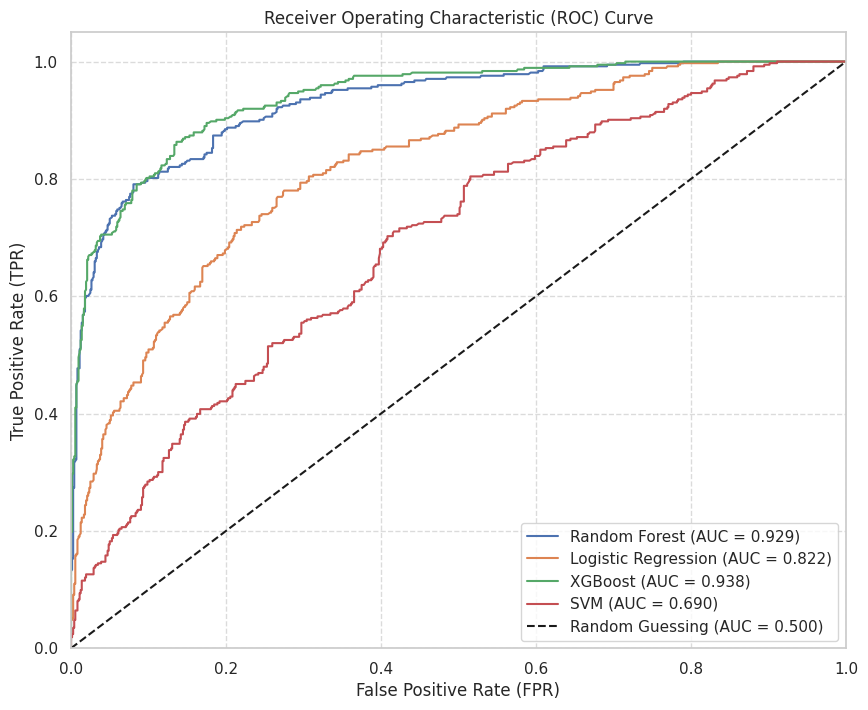

In [12]:
plt.figure(figsize=(10, 8))

for name, pipeline in results.items():
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_binary, y_probs)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# Plot random guessing reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

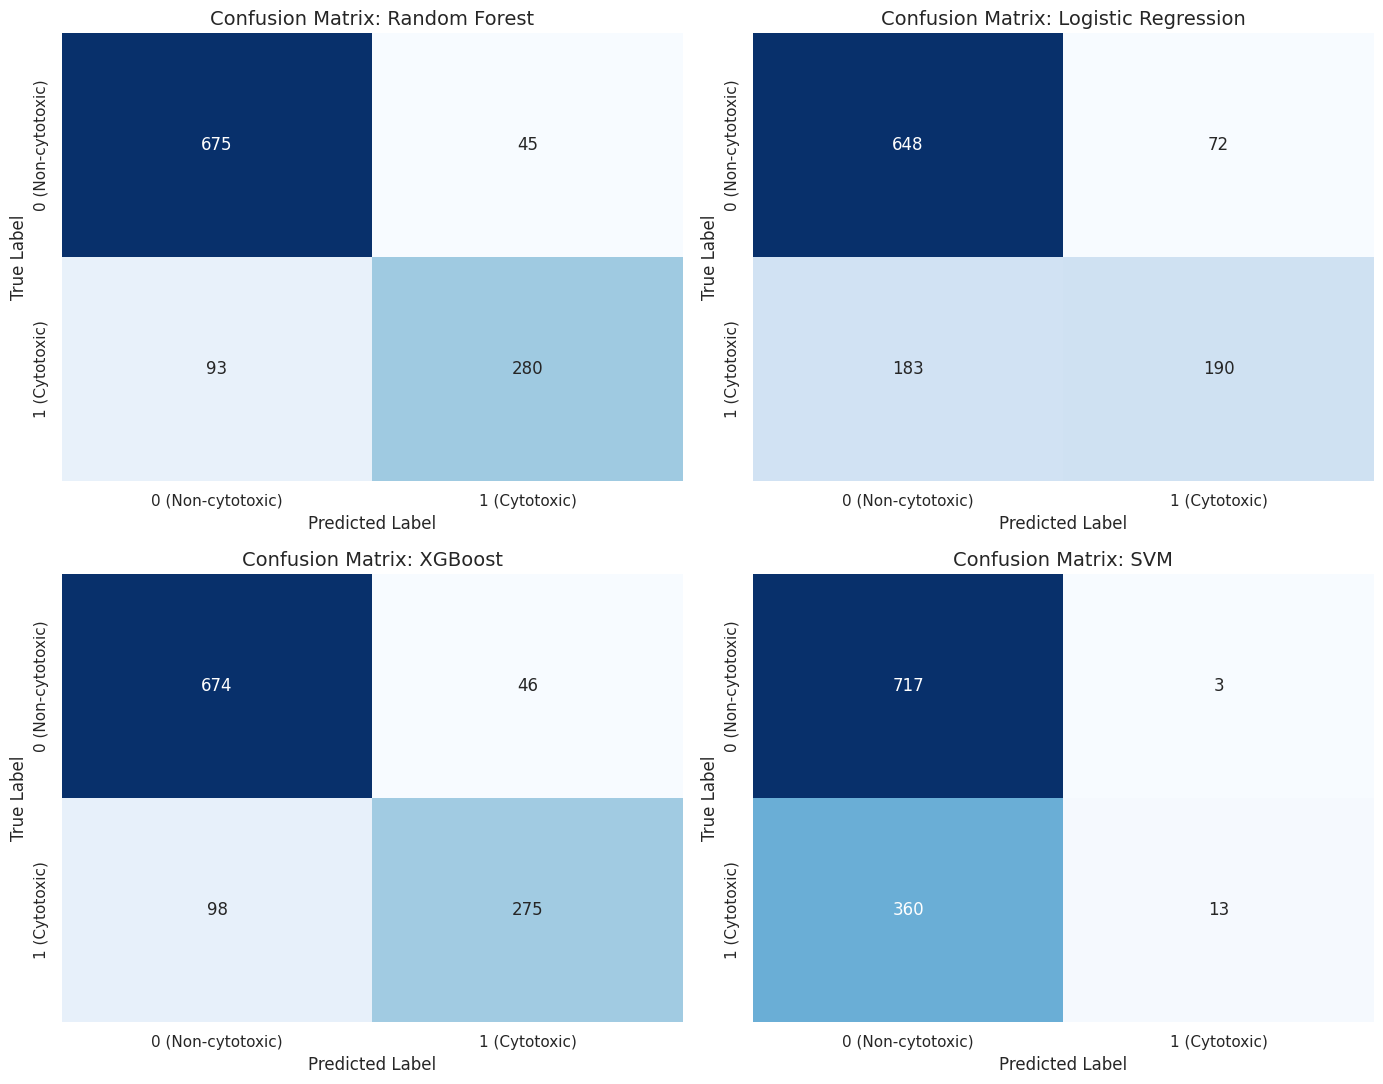

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.ravel()

for i, (name, pipeline) in enumerate(results.items()):
    pred = predictions[name]
    cm = confusion_matrix(y_test_binary, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i],
        cbar=False,
        xticklabels=['0 (Non-cytotoxic)', '1 (Cytotoxic)'],
        yticklabels=['0 (Non-cytotoxic)', '1 (Cytotoxic)']
    )

    axes[i].set_title(f'Confusion Matrix: {name}', fontsize=14)
    axes[i].set_xlabel('Predicted Label', fontsize=12)
    axes[i].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

In [14]:
y_train_binary.to_csv('y_train_binary_cyto.csv', index=False)
y_test_binary.to_csv('y_test_binary_cyto.csv', index=False)
evaluation_ml_sel_binary.to_csv('evaluation_ml_cyto_binary.csv', index=False)